### import's

In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
from numpy import loadtxt
from keras.models import Sequential
from keras.layers import Dense, Input, Dropout, BatchNormalization, Activation
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler
from numpy import exp
from tensorflow.keras import Model

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,mean_absolute_error,mean_squared_error
from sklearn.model_selection import GridSearchCV
from keras.wrappers.scikit_learn import KerasRegressor,KerasClassifier


### def model

In [3]:
def exp_decay(self, epoch):
    initial_lrate = 0.001
    k = 0.1
    lrate = initial_lrate * exp(-k*epoch)
    return lrate


def create_model_neurons(optimizer='Adam',layers=1,dropout = 0.15, neurons=64,epochs=100,norm=True, activation='relu'):
    # create model
    model = Sequential()
    model.add(Dense(neurons, input_dim=13, kernel_initializer='uniform'))
    if norm:
        model.add(BatchNormalization())
    model.add(Activation(activation))
    model.add(Dropout(dropout))
    for layer in range(layers):
        model.add(Dense(neurons, kernel_initializer='uniform'))
        if norm:
            model.add(BatchNormalization())
        model.add(Activation(activation))
        model.add(Dropout(dropout))
    model.add(Dense(1))
    # Compile model
    model.compile(loss='mean_squared_error',optimizer=optimizer, metrics=['mse'])
    return model

def build_model():
    model = Sequential()
    model.add(Dense(64, activation='relu', input_shape=(13,)))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(1))

    model.compile(optimizer='rmsprop',
              loss='mse',
              metrics=['mae'])
    return model

In [4]:
from sklearn.datasets import load_boston
boston_dataset = load_boston()
X_train, X_test, y_train, y_test = train_test_split(boston_dataset.data, boston_dataset.target, test_size=0.2, random_state=42)

## Get best model

In [5]:
from keras.datasets import boston_housing

(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

In [30]:
# create model

model = KerasRegressor(build_fn=create_model_neurons, epochs=100, batch_size=10, verbose=1)

lr_schedule_1 = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.1,
    decay_steps=100000,
    decay_rate=0.01)
lr_schedule_2 = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.5,
    decay_steps=100000,
    decay_rate=0.1)
lr_schedule_3 = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.05,
    decay_steps=100000,
    decay_rate=0.01)

#define the grid search parameters
optimizer = [tf.keras.optimizers.Adam(learning_rate=lr_schedule_1),
             tf.keras.optimizers.Adam(learning_rate=lr_schedule_2),
             tf.keras.optimizers.Adam(learning_rate=lr_schedule_3),]

epochs=[400]
neurons = [60,80,100]
layers =[0,1,2]
dropout=[ .25]
norm=[True,False]
activation = ['leaky_relu','relu']
param_grid = dict(epochs=epochs,layers=layers,dropout=dropout,optimizer=optimizer,neurons=neurons, norm=norm, activation=activation)

callabacks_list = [EarlyStopping(patience=50,monitor='loss')]
# define the grid search parameters

grid = GridSearchCV(estimator=model, param_grid=param_grid, cv=3,verbose=1)
grid_result = grid.fit(train_data, train_targets, batch_size=16,callbacks=callabacks_list)
# summarize results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Epoch 1/400


C:\Users\diego\AppData\Local\Temp/ipykernel_324508/41492667.py:3: DeprecationWarning: KerasRegressor is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead. See https://www.adriangb.com/scikeras/stable/migration.html for help migrating.
  model = KerasRegressor(build_fn=create_model_neurons, epochs=100, batch_size=10, verbose=1)


27/27 [==============================] - 1s 2ms/step - loss: 147.5430 - mse: 147.5430
Epoch 2/400
27/27 [==============================] - 0s 2ms/step - loss: 59.1800 - mse: 59.1800
Epoch 3/400
27/27 [==============================] - 0s 2ms/step - loss: 61.1398 - mse: 61.1398
Epoch 4/400
27/27 [==============================] - 0s 2ms/step - loss: 46.1328 - mse: 46.1328
Epoch 5/400
27/27 [==============================] - 0s 2ms/step - loss: 50.4047 - mse: 50.4047
Epoch 6/400
27/27 [==============================] - 0s 2ms/step - loss: 51.7910 - mse: 51.7910
Epoch 7/400
27/27 [==============================] - 0s 1ms/step - loss: 47.7290 - mse: 47.7290
Epoch 8/400
27/27 [==============================] - 0s 2ms/step - loss: 49.3228 - mse: 49.3228
Epoch 9/400
27/27 [==============================] - 0s 2ms/step - loss: 47.6917 - mse: 47.6917
Epoch 10/400
27/27 [==============================] - 0s 2ms/step - loss: 47.2845 - mse: 47.2845
Epoch 11/400
27/27 [=============================

27/27 [==============================] - 0s 2ms/step - loss: 36.9196 - mse: 36.9196
Epoch 24/400
27/27 [==============================] - 0s 2ms/step - loss: 41.6578 - mse: 41.6578
Epoch 25/400
27/27 [==============================] - 0s 2ms/step - loss: 43.6672 - mse: 43.6672
Epoch 26/400
27/27 [==============================] - 0s 1ms/step - loss: 63.8088 - mse: 63.8088
Epoch 27/400
27/27 [==============================] - 0s 1ms/step - loss: 41.7509 - mse: 41.7509
Epoch 28/400
27/27 [==============================] - 0s 1ms/step - loss: 37.3496 - mse: 37.3496
Epoch 29/400
27/27 [==============================] - 0s 1ms/step - loss: 45.7680 - mse: 45.7680
Epoch 30/400
27/27 [==============================] - 0s 2ms/step - loss: 38.8970 - mse: 38.8970
Epoch 31/400
27/27 [==============================] - 0s 2ms/step - loss: 31.6298 - mse: 31.6298
Epoch 32/400
27/27 [==============================] - 0s 2ms/step - loss: 41.1326 - mse: 41.1326
Epoch 33/400
27/27 [=======================

27/27 [==============================] - 0s 1ms/step - loss: 44.0033 - mse: 44.0033
Epoch 29/400
27/27 [==============================] - 0s 1ms/step - loss: 40.2304 - mse: 40.2304
Epoch 30/400
27/27 [==============================] - 0s 2ms/step - loss: 33.2443 - mse: 33.2443
Epoch 31/400
27/27 [==============================] - 0s 2ms/step - loss: 43.7709 - mse: 43.7709
Epoch 32/400
27/27 [==============================] - 0s 2ms/step - loss: 31.8475 - mse: 31.8475
Epoch 33/400
27/27 [==============================] - 0s 1ms/step - loss: 30.8425 - mse: 30.8425
Epoch 34/400
27/27 [==============================] - 0s 1ms/step - loss: 27.4235 - mse: 27.4235
Epoch 35/400
27/27 [==============================] - 0s 1ms/step - loss: 25.3114 - mse: 25.3114
Epoch 36/400
27/27 [==============================] - 0s 1ms/step - loss: 36.5471 - mse: 36.5471
Epoch 37/400
27/27 [==============================] - 0s 1ms/step - loss: 30.7228 - mse: 30.7228
Epoch 38/400
27/27 [=======================

14/14 [==============================] - 0s 1ms/step - loss: 26.8191 - mse: 26.8191
Epoch 1/400
27/27 [==============================] - 1s 2ms/step - loss: 229.2007 - mse: 229.2007
Epoch 2/400
27/27 [==============================] - 0s 1ms/step - loss: 82.3324 - mse: 82.3324
Epoch 3/400
27/27 [==============================] - 0s 1ms/step - loss: 82.4324 - mse: 82.4324
Epoch 4/400
27/27 [==============================] - 0s 2ms/step - loss: 67.8745 - mse: 67.8745
Epoch 5/400
27/27 [==============================] - 0s 2ms/step - loss: 66.9678 - mse: 66.9678
Epoch 6/400
27/27 [==============================] - 0s 2ms/step - loss: 70.7516 - mse: 70.7516
Epoch 7/400
27/27 [==============================] - 0s 2ms/step - loss: 64.1035 - mse: 64.1035
Epoch 8/400
27/27 [==============================] - 0s 2ms/step - loss: 76.1092 - mse: 76.1092
Epoch 9/400
27/27 [==============================] - 0s 1ms/step - loss: 54.4736 - mse: 54.4736
Epoch 10/400
27/27 [==============================

... (357 outputs left out)

27/27 [==============================] - 0s 2ms/step - loss: 104.5848 - mse: 104.5848
Epoch 93/400
27/27 [==============================] - 0s 2ms/step - loss: 111.8417 - mse: 111.8417
Epoch 94/400
27/27 [==============================] - 0s 1ms/step - loss: 103.2339 - mse: 103.2339
Epoch 95/400
27/27 [==============================] - 0s 2ms/step - loss: 109.7608 - mse: 109.7608
Epoch 96/400
27/27 [==============================] - 0s 2ms/step - loss: 108.7491 - mse: 108.7491
Epoch 97/400
27/27 [==============================] - 0s 2ms/step - loss: 99.8199 - mse: 99.8199
Epoch 98/400
27/27 [==============================] - 0s 2ms/step - loss: 110.0947 - mse: 110.0947
Epoch 99/400
27/27 [==============================] - 0s 2ms/step - loss: 111.0333 - mse: 111.0333
Epoch 100/400
27/27 [==============================] - 0s 1ms/step - loss: 106.7816 - mse: 106.7816
Epoch 101/400
27/27 [==============================] - 0s 2ms/step - loss: 100.3495 - mse: 100.3495
Epoch 102/400
27/27 [==

27/27 [==============================] - 0s 2ms/step - loss: 80.5974 - mse: 80.5974
Epoch 83/400
27/27 [==============================] - 0s 2ms/step - loss: 85.7599 - mse: 85.7599
Epoch 84/400
27/27 [==============================] - 0s 2ms/step - loss: 80.9315 - mse: 80.9315
Epoch 85/400
27/27 [==============================] - 0s 2ms/step - loss: 89.3962 - mse: 89.3962
Epoch 86/400
27/27 [==============================] - 0s 1ms/step - loss: 86.1255 - mse: 86.1255
Epoch 87/400
27/27 [==============================] - 0s 2ms/step - loss: 91.1189 - mse: 91.1189
Epoch 88/400
27/27 [==============================] - 0s 1ms/step - loss: 84.9322 - mse: 84.9322
Epoch 89/400
27/27 [==============================] - 0s 2ms/step - loss: 81.7149 - mse: 81.7149
Epoch 90/400
27/27 [==============================] - 0s 2ms/step - loss: 83.3846 - mse: 83.3846
Epoch 91/400
27/27 [==============================] - 0s 2ms/step - loss: 88.8752 - mse: 88.8752
Epoch 92/400
27/27 [=======================

41/41 [==============================] - 0s 2ms/step - loss: 35.6606 - mse: 35.6606
Epoch 69/400
41/41 [==============================] - 0s 2ms/step - loss: 29.0167 - mse: 29.0167
Epoch 70/400
41/41 [==============================] - 0s 2ms/step - loss: 31.6123 - mse: 31.6123
Epoch 71/400
41/41 [==============================] - 0s 2ms/step - loss: 34.0026 - mse: 34.0026
Epoch 72/400
41/41 [==============================] - 0s 2ms/step - loss: 34.9709 - mse: 34.9709
Epoch 73/400
41/41 [==============================] - 0s 2ms/step - loss: 37.6677 - mse: 37.6677
Epoch 74/400
41/41 [==============================] - 0s 2ms/step - loss: 30.7072 - mse: 30.7072
Epoch 75/400
41/41 [==============================] - 0s 2ms/step - loss: 34.1136 - mse: 34.1136
Epoch 76/400
41/41 [==============================] - 0s 2ms/step - loss: 31.9371 - mse: 31.9371
Epoch 77/400
41/41 [==============================] - 0s 2ms/step - loss: 34.0924 - mse: 34.0924
Epoch 78/400
41/41 [=======================

41/41 [==============================] - 0s 2ms/step - loss: 28.7954 - mse: 28.7954
Epoch 153/400
41/41 [==============================] - 0s 2ms/step - loss: 24.6922 - mse: 24.6922
Epoch 154/400
41/41 [==============================] - 0s 2ms/step - loss: 30.8020 - mse: 30.8020
Epoch 155/400
41/41 [==============================] - 0s 2ms/step - loss: 27.0349 - mse: 27.0349
Epoch 156/400
41/41 [==============================] - 0s 2ms/step - loss: 36.1765 - mse: 36.1765
Epoch 157/400
41/41 [==============================] - 0s 2ms/step - loss: 27.2566 - mse: 27.2566
Epoch 158/400
41/41 [==============================] - 0s 2ms/step - loss: 24.9805 - mse: 24.9805
Epoch 159/400
41/41 [==============================] - 0s 2ms/step - loss: 27.2646 - mse: 27.2646
Epoch 160/400
41/41 [==============================] - 0s 2ms/step - loss: 30.1008 - mse: 30.1008
Epoch 161/400
41/41 [==============================] - 0s 2ms/step - loss: 23.9196 - mse: 23.9196
Epoch 162/400
41/41 [=============

In [31]:
mean_absolute_error(test_targets,grid_result.best_estimator_.predict(test_data))

11/11 [==============================] - 0s 2ms/step


3.994890046587178

In [ ]:
model = create_model_neurons()
model.fit(train_data, train_targets, epochs=80, batch_size=16, verbose=0)

In [82]:
mlp_regressor=create_model_neurons()
mlp_regressor.fit(train_data, np.log1p(train_targets), epochs=400, batch_size=16, verbose=0)
mean_absolute_error(test_targets,np.expm1(mlp_regressor.predict(test_data)))

3.336852313022987

In [58]:
def build_model():
    model = Sequential()
    model.add(Dense(64, activation='relu', input_shape=(13,)))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(1))

    model.compile(optimizer='Adam',
              loss='mse',
              metrics=['mse'])
    return model
def create_model_neurons(optimizer='Adam',layers=1,dropout = .15, neurons=80,epochs=100,norm=True, activation='relu'):
    # create model
    model = Sequential()
    model.add(Dense(neurons, input_dim=13, kernel_initializer='uniform'))
    if norm:
        model.add(BatchNormalization())
    model.add(Activation(activation))
    model.add(Dropout(dropout))
    for layer in range(layers):
        model.add(Dense(neurons, kernel_initializer='uniform'))
        if norm:
            model.add(BatchNormalization())
        model.add(Activation(activation))
        #model.add(Dropout(dropout))
    model.add(Dense(1))
    # Compile model
    model.compile(loss='mean_squared_error',optimizer=optimizer, metrics=['mse'])
    return model

In [60]:
mlp_regressor=create_model_neurons()
mlp_regressor.fit(train_data, train_targets, epochs=400, batch_size=16, verbose=0)
mean_absolute_error(test_targets,mlp_regressor.predict(test_data))

3.146913464864095

In [61]:
mean_squared_error(test_targets,mlp_regressor.predict(test_data))

23.241495176001905

### PLot Model

In [8]:
grid_result.best_params_

{'activation': 'relu',
 'dropout': 0.25,
 'epochs': 400,
 'layers': 2,
 'neurons': 80,
 'norm': True,
 'optimizer': <keras.optimizer_v2.adam.Adam at 0x203ea1f4b20>}

In [9]:
grid_result.best_estimator_.model.summary()

Model: "sequential_144"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_432 (Dense)           (None, 80)                1120      
                                                                 
 batch_normalization_144 (Ba  (None, 80)               320       
 tchNormalization)                                               
                                                                 
 activation_288 (Activation)  (None, 80)               0         
                                                                 
 dropout_288 (Dropout)       (None, 80)                0         
                                                                 
 dense_433 (Dense)           (None, 80)                6480      
                                                                 
 batch_normalization_145 (Ba  (None, 80)               320       
 tchNormalization)                                  

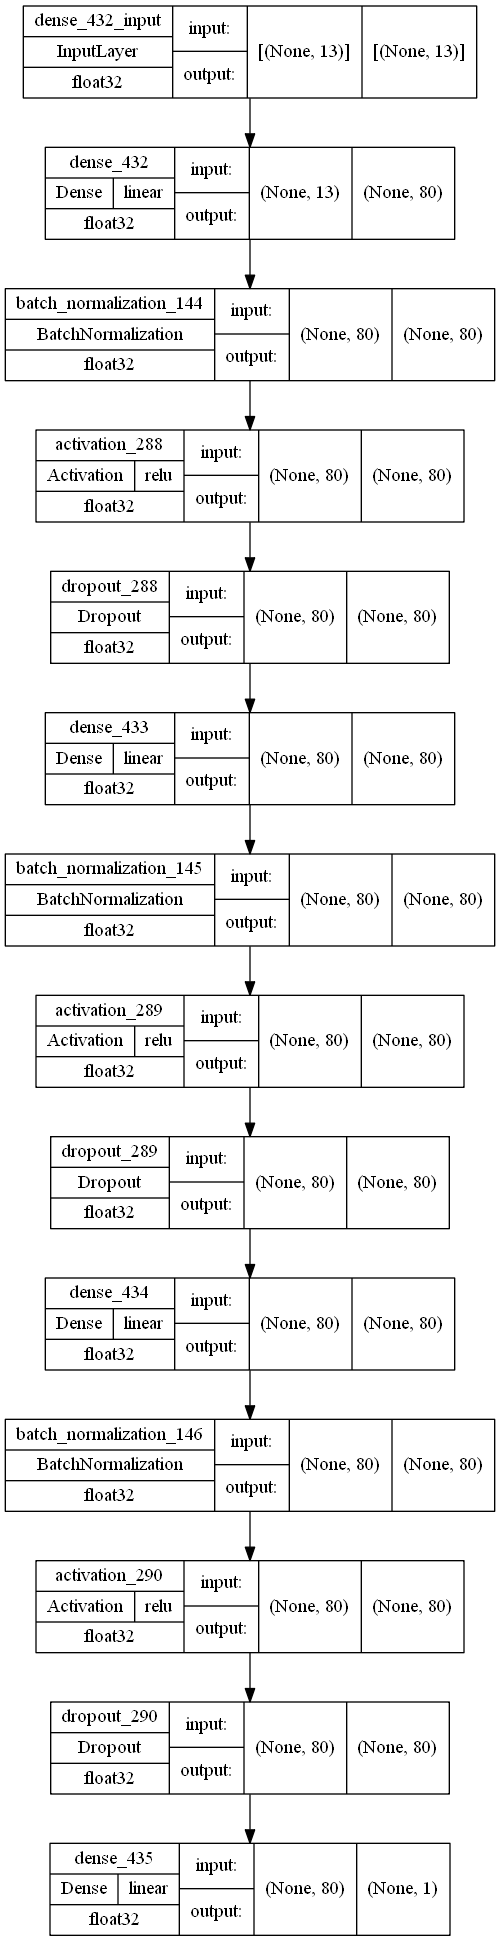

In [10]:
import keras
import pydotplus
from keras.utils.vis_utils import plot_model
keras.utils.vis_utils.pydot = pydotplus
plot_model(grid_result.best_estimator_.model, to_file='model.png',show_dtype=True, show_shapes=True, show_layer_activations=True)

## RandomForestRegressor

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
param_grid = {'bootstrap': [True, False],
 'max_depth': [10, 20, 30],
 'max_features': ['auto', 'sqrt'],
 'min_samples_leaf': [1, 2, 4],
 'min_samples_split': [2, 5, 10],
 'n_estimators': [100,200, 300]}

In [ ]:
# Create a based model
rf = RandomForestRegressor()

grid_search = GridSearchCV(estimator = rf, param_grid = param_grid, 
                          cv = 3, n_jobs = -1, verbose = 2)
grid_search.fit(train_data, train_targets)



In [ ]:
mean_absolute_error(test_targets,grid_search.predict(test_data))

In [ ]:
mean_squared_error(test_targets,grid_search.predict(test_data))

# XGBRegressor

In [ ]:
from xgboost import XGBRegressor

In [ ]:
gsc = GridSearchCV(
            estimator=XGBRegressor(),
            param_grid={"learning_rate": (0.05, 0.10, 0.15),
                        "max_depth": [ 3, 4, 5, 6, 8],
                        "min_child_weight": [ 1, 3, 5, 7],
                        "gamma":[ 0.0, 0.1, 0.2],
                        "colsample_bytree":[ 0.3, 0.4],},
            cv=3, scoring='neg_mean_squared_error', verbose=0, n_jobs=-1)
gsc.fit(train_data, train_targets)

In [ ]:
mean_absolute_error(test_targets,gsc.predict(test_data))

In [ ]:
mean_squared_error(test_targets,gsc.predict(test_data))